# Gradient clipping check and β sweep

1. **Clipping:** measure unclipped gradient norms on real batches and choose `max_grad_norm` so that clipping catches only rare spikes.
2. **β:** train short runs on fold 0 of a file subset, one per β. Pick the β that recovers the most known transients at a fixed false-positive rate. Validation loss can't choose β: losses with different β aren't comparable, and lower β always gives lower reconstruction error.

In [10]:
from pathlib import Path
import importlib, json, sys
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

sys.path.insert(0, "/pscratch/sd/z/zixinq")
import vae_model as vae_lib
vae_lib = importlib.reload(vae_lib)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

BASE_CKPT = Path("/pscratch/sd/z/zixinq/vae_v2_run1/best.pt")   # configs only
CLIP_CKPT = Path("/pscratch/sd/z/zixinq/vae_v2_run1/latest.pt")  # a trained model for the clip check
TRANSIENT_FILE = Path("/global/cfs/cdirs/desi/users/zixinq/data/dr2_catalog/transients_preprocessed_all.npz")
SWEEP_DIR = Path("/pscratch/sd/z/zixinq/vae_tuning")

base = torch.load(BASE_CKPT, map_location="cpu", weights_only=True)
model_config, base_data_config = dict(base["model_config"]), dict(base["data_config"])
del base

## 1. Clipping fraction

`max_grad_norm=5` is compared with the norm of the gradient of the **batch-summed** loss (256 spectra × about 1000 pixels), so it is likely far above 5 on every step. Gradients are measured both at initialization and at a trained checkpoint, because norms change during training. Nothing is saved; BatchNorm statistics of the in-memory copy change but are discarded.

In [3]:
def gradient_norms(model, loader, beta, n_batches=200):
    model.train()
    norms = []
    for i, (x, w, _, _) in enumerate(loader):
        if i == n_batches:
            break
        x, w = vae_lib.masked_inputs(x.to(device), w.to(device))
        model.zero_grad(set_to_none=True)
        recon, mu, logvar, _ = model(x, sample=True)
        vae_lib.vae_loss(x, recon, mu, logvar, w, beta)[0].backward()
        norms.append(torch.nn.utils.clip_grad_norm_(model.parameters(), float("inf")).item())
    return np.array(norms)


loader = vae_lib.make_h5_loader(
    vae_lib.H5SpectralBatches(**base_data_config, split="train", shuffle=True), device)
models = {"fresh init": vae_lib.VAE(**model_config).to(device)}
trained = vae_lib.VAE(**model_config).to(device)
trained.load_state_dict(torch.load(CLIP_CKPT, map_location="cpu", weights_only=True)["model_state_dict"])
models["trained"] = trained

for name, m in models.items():
    g = gradient_norms(m, loader, beta=1e-3)
    p50, p95, p99 = np.percentile(g, [50, 95, 99])
    print(f"{name:10s} grad norm median {p50:.3g}  p95 {p95:.3g}  p99 {p99:.3g}  "
          f"clipped at 5: {np.mean(g > 5):.0%}")

KeyboardInterrupt: 

**How to read it.** If almost 100% of steps exceed 5, every update is rescaled to norm 5. Adam still makes progress, because it normalizes step sizes anyway. But batches lose their relative weighting, and a genuine spike is indistinguishable from an ordinary step.

Set `MAX_GRAD_NORM` near the **trained model's 99th percentile**, so clipping fires on about 1% of steps. Then check the `clipped=` column in the new training logs. If clipping fires often early on and rarely later, that's normal.

A different `max_grad_norm` needs a new run, because `fit_vae` refuses to resume with changed settings. Start the sweep below and the cross-validation runs with the new value.

In [7]:
MAX_GRAD_NORM = 3e7

## 2. β sweep

The sweep uses fold 0 on a random subset of files, with a few epochs per β. The relative ranking of β values is usually stable at this scale; confirm the top two on full data if they are close.

For each β the notebook records:
- **Validation reduced χ²**: reconstruction quality, about 1 at noise level.
- **Validation KL**.
- **Active latent units**: latent dimensions whose μ varies across spectra (variance > 0.01). Many inactive units at large β means posterior collapse.
- **Transient recall at fixed FPR**, using three scores: raw reduced χ²; reduced χ² divided by `1 + (ε·SNR)²` (the error-floor correction, with ε fitted from that model's holdout spectra); and kNN distance in standardized μ.

Known transients are excluded from training and from the comparison population.

In [11]:
BETAS = [1e-3, 1e-2, 1e-1, 1.0]
FILE_FRACTION = 0.2
SWEEP_EPOCHS = 8
FPR_LEVELS = [1e-2, 1e-3]
SEED = 42

sweep_train_config = dict(
    epochs=SWEEP_EPOCHS, learning_rate=3e-4, warmup_epochs=2, patience=3,
    weight_power=1.0, max_grad_norm=MAX_GRAD_NORM, log_every=2000, checkpoint_every_batches=2000,
)

files = list(vae_lib.resolve_hdf5_files(base_data_config["path"]))
rng = np.random.default_rng(SEED)
subset = sorted(rng.choice(files, max(1, int(FILE_FRACTION * len(files))), replace=False).tolist())
sweep_data_config = dict(base_data_config, path=subset, n_folds=2, fold=0)
print(f"sweep uses {len(subset)} of {len(files)} files")

# Transients: X, W, M arrays with M == 1 marking valid pixels (as in the earlier check).
with np.load(TRANSIENT_FILE, allow_pickle=True) as d:
    X_tr = d["X"].reshape(len(d["X"]), -1).astype(np.float32)
    W_tr = d["W"].reshape(X_tr.shape).astype(np.float32)
    if "M" in d:
        W_tr = np.where(d["M"].reshape(X_tr.shape) == 1, W_tr, 0).astype(np.float32)
    tid_tr = np.asarray(d["TARGETID"]).astype(np.int64)
print(f"{len(X_tr)} transients")


def sweep_loader(split, shuffle=False):
    ds = vae_lib.H5SpectralBatches(**sweep_data_config, split=split, shuffle=shuffle,
                                   exclude_targetids=tid_tr)
    return vae_lib.make_h5_loader(ds, device)


@torch.inference_mode()
def score_arrays(model, X, W, batch=1024):
    model.eval()
    out = {"mu": [], "rchi2": [], "snr": []}
    for s in range(0, len(X), batch):
        x, w = vae_lib.masked_inputs(torch.as_tensor(X[s:s + batch], device=device),
                                     torch.as_tensor(W[s:s + batch], device=device))
        recon, mu, _, _ = model(x, sample=False)
        r = vae_lib._tensor_spectra_2d(recon) - x
        valid = w > 0
        out["rchi2"].append(((w * r.square()).sum(1) / valid.sum(1).clamp_min(1)).cpu())
        out["snr"].append(torch.where(valid, x * w.sqrt(), torch.nan).nanmedian(1).values.cpu())
        out["mu"].append(mu.float().cpu())
    return {k: torch.cat(v).numpy() for k, v in out.items()}


def fit_eps(snr, rchi2, nbins=20):
    ok = np.isfinite(snr) & (snr > 0)
    edges = np.quantile(snr[ok], np.linspace(0, 1, nbins + 1))
    b = np.clip(np.searchsorted(edges, snr[ok], side="right") - 1, 0, nbins - 1)
    s = np.array([np.median(snr[ok][b == i]) for i in range(nbins)])
    m = np.array([np.median(rchi2[ok][b == i]) for i in range(nbins)])
    return float(np.sqrt(max(np.sum((m - 1) * s**2) / np.sum(s**4), 0)))


def fpr_of(x, population):
    pop = np.sort(population)
    return (1 + len(pop) - np.searchsorted(pop, x, side="left")) / (len(pop) + 1)

sweep uses 337 of 1688 files
726 transients


In [12]:
for beta in BETAS:
    out_dir = SWEEP_DIR / f"beta_{beta:g}"
    if (out_dir / "sweep_scores.npz").is_file():
        print(f"beta={beta:g}: done, skipping")
        continue
    print(f"\n===== beta = {beta:g} =====")
    latest = out_dir / "latest.pt"
    vae_lib.seed_everything(SEED)
    model = vae_lib.VAE(**model_config).to(device)   # same init for every beta
    vae_lib.fit_vae(model, sweep_loader("train", shuffle=True), sweep_loader("val"), device,
                    out_dir=out_dir, data_config=sweep_data_config,
                    resume_from=latest if latest.is_file() else None,
                    beta_max=beta, **sweep_train_config)
    hold = vae_lib.score_spectra(model, sweep_loader("holdout"), device)
    val = vae_lib.score_spectra(model, sweep_loader("val"), device)
    tr = score_arrays(model, X_tr, W_tr)
    np.savez(out_dir / "sweep_scores.npz",
             **{f"hold_{k}": v for k, v in hold.items()},
             val_mu=val["mu"], **{f"tr_{k}": v for k, v in tr.items()})


===== beta = 0.001 =====
Checkpoint: /pscratch/sd/z/zixinq/vae_tuning/beta_0.001/latest.pt
Saved epoch 1, batch 2,000.
  batches=2,000 spectra=459,619 rec=36111.1 kl=29005 rchi2=72.23 clipped=88%
Saved epoch 1, batch 4,000.
  batches=4,000 spectra=921,727 rec=19944.2 kl=45865.2 rchi2=39.89 clipped=79%
Saved epoch 1, batch 6,000.
  batches=6,000 spectra=1,382,133 rec=14957 kl=60473.6 rchi2=29.92 clipped=71%
Saved epoch 1, batch 8,000.
  batches=8,000 spectra=1,843,737 rec=12077.5 kl=71473.9 rchi2=24.16 clipped=65%
Saved epoch 1, batch 10,000.
  batches=10,000 spectra=2,304,147 rec=10203.3 kl=78270.5 rchi2=20.41 clipped=60%
Saved epoch 1, batch 12,000.
  batches=12,000 spectra=2,764,908 rec=10645.4 kl=83865 rchi2=21.29 clipped=57%
epoch=001 beta=0.0005 train_rec=10212.3 val_rec=2657.23 val_KL=114885 val_rchi2=5.315 clipped=56% time=16.2 min
Saved epoch 2, batch 2,000.
  batches=2,000 spectra=459,891 rec=6573.09 kl=96024.8 rchi2=13.15 clipped=44%
Saved epoch 2, batch 4,000.
  batches=4,0

KeyboardInterrupt: 

,best_epoch,val_rchi2,val_kl,active_units,eps,clip_frac,rchi2@0.01,rchi2@0.001,rchi2_snr@0.01,rchi2_snr@0.001,knn@0.01,knn@0.001
beta,,,,,,,,,,,,
0.001,6,2.8419,17393.7608,16,0.0256,0.1216,0.2025,0.0262,0.2121,0.0468,0.3815,0.0868
0.010,6,2.8370,1946.8870,16,0.0260,0.1204,0.2121,0.0303,0.2135,0.0482,0.3719,0.0758


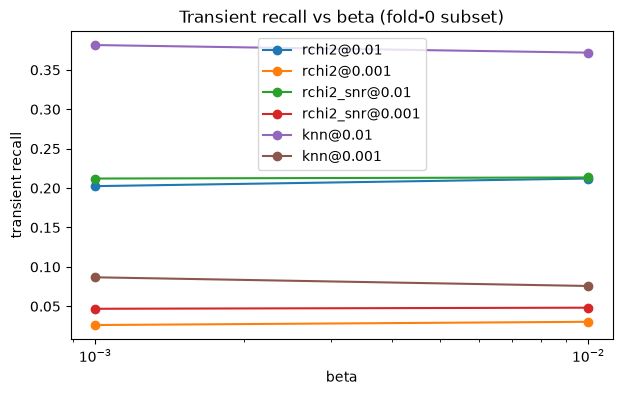

In [27]:
BETAS = [1e-3, 1e-2]
rows = []
for beta in BETAS:
    out_dir = SWEEP_DIR / f"beta_{beta:g}"
    d = dict(np.load(out_dir / "sweep_scores.npz"))
    hist = json.loads((out_dir / "history.json").read_text())
    best = min(hist, key=lambda h: h["val_loss"])

    pop = ~np.isin(d["hold_TARGETID"], tid_tr)
    eps = fit_eps(d["hold_snr"][pop], d["hold_rchi2"][pop])
    corr = lambda r, s: r / (1 + (eps * np.nan_to_num(s)) ** 2)

    ref = d["val_mu"][np.random.default_rng(SEED).choice(len(d["val_mu"]), min(20000, len(d["val_mu"])), replace=False)]
    scaler = StandardScaler().fit(ref)
    knn = NearestNeighbors(n_neighbors=35).fit(scaler.transform(ref))
    knn_score = lambda mu: knn.kneighbors(scaler.transform(mu))[0].mean(1)

    scores = {
        "rchi2": (d["hold_rchi2"][pop], d["tr_rchi2"]),
        "rchi2_snr": (corr(d["hold_rchi2"][pop], d["hold_snr"][pop]), corr(d["tr_rchi2"], d["tr_snr"])),
        "knn": (knn_score(d["hold_mu"][pop]), knn_score(d["tr_mu"])),
    }
    row = dict(beta=beta, best_epoch=best["epoch"], val_rchi2=best["val_rchi2"], val_kl=best["val_kl"],
               active_units=int((d["hold_mu"].var(0) > 0.01).sum()), eps=eps,
               clip_frac=best.get("train_clip_frac"))
    for name, (population, positives) in scores.items():
        f = fpr_of(positives, population)
        for a in FPR_LEVELS:
            row[f"{name}@{a:g}"] = float(np.mean(f <= a))
    rows.append(row)

table = pd.DataFrame(rows).set_index("beta")
display(table.round(4))

recall_cols = [c for c in table.columns if "@" in c]
table[recall_cols].plot(marker="o", logx=True, figsize=(7, 4))
plt.ylabel("transient recall"); plt.title("Transient recall vs beta (fold-0 subset)")
plt.show()

**Choosing β.** Pick the β with the highest recall at the FPR you would actually inspect (for example 10⁻³) for your main score. If two values are within noise (with about 700 transients, differences under about 3% are not significant), prefer the larger β: its latent space is more regular, which helps the latent detectors. Then set `beta_max` to that value in `train_config` of `vae_training.ipynb` and run the cross-validation from scratch.

The same transients are used both to choose β and, later, to report recall, so the reported recall is slightly optimistic. To avoid that, choose β with injected simulations or half the transients, and report recall on the rest.

## 3. Reconstructions and latent space for each run

Runs are found from the folders in `SWEEP_DIR` that contain a `best.pt`. Each run's β and contrastive weight λ are read from its checkpoint. Reconstructions need only `best.pt`; the latent-space plots also need the run's `sweep_scores.npz`, which is written after training finishes.

The same example spectra are used for every run: `N_PER_CLASS` held-out spectra of each SPECTYPE, plus `N_TRANSIENTS` known transients.

In [ ]:
import h5py
import math

PLOT_RUNS = "all"        # "all", "no_contrast", "contrast", or a list of folder names, e.g. ["beta_0.001"]
CLASSES = ["GALAXY", "QSO", "STAR"]
N_PER_CLASS = 3
N_TRANSIENTS = 3
N_LATENT_PER_CLASS = 5000
MAX_SEARCH_BATCHES = 2000
colors = {"GALAXY": "C0", "QSO": "C2", "STAR": "C4"}


def run_info(run_dir):
    ckpt = torch.load(run_dir / "best.pt", map_location="cpu", weights_only=True)
    tc = ckpt["train_config"]
    return dict(beta=tc["beta_max"], contrast=tc.get("contrast_weight", 0.0), epoch=ckpt["epoch"])


RUN_INFO = {p.parent.name: run_info(p.parent) for p in SWEEP_DIR.glob("*/best.pt")}


def select_runs(choice):
    names = sorted(RUN_INFO, key=lambda n: (RUN_INFO[n]["contrast"], RUN_INFO[n]["beta"]))
    if choice == "all":
        return names
    if choice == "no_contrast":
        return [n for n in names if not RUN_INFO[n]["contrast"]]
    if choice == "contrast":
        return [n for n in names if RUN_INFO[n]["contrast"]]
    return [n for n in choice if n in RUN_INFO]


def run_label(name):
    info = RUN_INFO[name]
    label = f"β={info['beta']:g}" + (f", λ={info['contrast']:g}" if info["contrast"] else "")
    return f"{name} ({label}, epoch {info['epoch']})"


runs = select_runs(PLOT_RUNS)
print("runs found:", {n: RUN_INFO[n] for n in runs})
if not runs:
    print(f"No run folder with best.pt in {SWEEP_DIR}.")

# Fixed example spectra from the holdout fold (the same for every run).
found = {c: [] for c in CLASSES}
for b, (x, w, lab, tid) in enumerate(sweep_loader("holdout")):
    for i in np.flatnonzero(np.isin(lab, CLASSES) & ~np.isin(tid, tid_tr)):
        if len(found[lab[i]]) < N_PER_CLASS:
            found[lab[i]].append((x[i].numpy(), w[i].numpy(), f"{lab[i]} {tid[i]}"))
    if all(len(v) == N_PER_CLASS for v in found.values()) or b >= MAX_SEARCH_BATCHES:
        break
print("example spectra per class:", {c: len(v) for c, v in found.items()})
examples = [e for c in CLASSES for e in found[c]]
examples += [(X_tr[i], W_tr[i], f"TRANSIENT {tid_tr[i]}") for i in range(min(N_TRANSIENTS, len(X_tr)))]
X_ex = np.stack([e[0] for e in examples]).astype(np.float32)
W_ex = np.stack([e[1] for e in examples]).astype(np.float32)
ex_names = [e[2] for e in examples]

with h5py.File(subset[0], "r") as f:
    wave = f["wave_grid"][:] if "wave_grid" in f else np.arange(X_ex.shape[1])

try:
    import umap
    method = "UMAP"
    make_reducer = lambda: umap.UMAP(n_neighbors=30, min_dist=0.1, random_state=SEED)
except ImportError:
    from sklearn.decomposition import PCA
    method = "PCA"
    make_reducer = lambda: PCA(n_components=2)


def load_checkpoint(path):
    ckpt = torch.load(path, map_location="cpu", weights_only=True)
    model = vae_lib.VAE(**ckpt["model_config"]).to(device)
    model.load_state_dict(ckpt["model_state_dict"])
    model.eval()
    return model, ckpt["epoch"]


@torch.inference_mode()
def plot_reconstructions(model, title, save_path=None):
    # Flux + reconstruction (left) and residual / sigma (right) for the example spectra.
    x, w = vae_lib.masked_inputs(torch.as_tensor(X_ex, device=device), torch.as_tensor(W_ex, device=device))
    rec = vae_lib._tensor_spectra_2d(model(x, sample=False)[0]).cpu().numpy()
    x, w = x.cpu().numpy(), w.cpu().numpy()
    n = len(x)
    fig, axes = plt.subplots(n, 2, figsize=(14, 1.9 * n), sharex=True, squeeze=False,
                             gridspec_kw=dict(width_ratios=[3, 2]))
    rchi2 = {}
    for i in range(n):
        good = w[i] > 0
        pull = (x[i] - rec[i]) * np.sqrt(w[i])
        rchi2[ex_names[i]] = float(np.mean(pull[good] ** 2))
        axes[i, 0].plot(wave, np.where(good, x[i], np.nan), color="0.35", lw=0.5)
        axes[i, 0].plot(wave, np.where(good, rec[i], np.nan), color="C1", lw=0.9)
        axes[i, 0].text(0.01, 0.84, f"{ex_names[i]}   rχ² = {rchi2[ex_names[i]]:.2f}",
                        transform=axes[i, 0].transAxes, fontsize=8)
        axes[i, 1].plot(wave, np.where(good, pull, np.nan), color="C0", lw=0.4)
        axes[i, 1].axhline(0, color="k", lw=0.5)
        axes[i, 1].set_ylim(-6, 6)
    axes[0, 0].set_title("flux (grey) and reconstruction (orange)", fontsize=10)
    axes[0, 1].set_title("residual / σ", fontsize=10)
    axes[-1, 0].set_xlabel("wavelength")
    axes[-1, 1].set_xlabel("wavelength")
    fig.suptitle(title, y=1.0)
    fig.tight_layout()
    if save_path is not None:
        fig.savefig(save_path, dpi=130, bbox_inches="tight")
    plt.show()
    return rchi2


def plot_latent(ax, mu, labels, mu_transients, title):
    # 2-D embedding fit on normal spectra only; transients are projected into it.
    labels = np.char.upper(np.char.strip(np.asarray(labels).astype(str)))
    rng = np.random.default_rng(SEED)   # same seed -> same spectra for every run
    idx = np.concatenate([
        rng.choice(pool, min(N_LATENT_PER_CLASS, len(pool)), replace=False)
        for c in CLASSES if len(pool := np.flatnonzero(labels == c))
    ])
    scaler = StandardScaler().fit(mu[idx])
    reducer = make_reducer().fit(scaler.transform(mu[idx]))
    xy = reducer.transform(scaler.transform(mu[idx]))
    xy_tr = reducer.transform(scaler.transform(mu_transients))
    lo, hi = np.percentile(xy, [0.5, 99.5], axis=0)
    lo, hi = lo - 0.15 * (hi - lo), hi + 0.15 * (hi - lo)
    outside = int(np.sum(np.any((xy_tr < lo) | (xy_tr > hi), axis=1)))
    xy_tr = np.clip(xy_tr, lo, hi)   # transients beyond the frame are drawn on its edge
    for c in CLASSES:
        m = labels[idx] == c
        if m.any():
            ax.scatter(xy[m, 0], xy[m, 1], s=2, alpha=0.35, color=colors.get(c), label=c, rasterized=True)
    ax.scatter(xy_tr[:, 0], xy_tr[:, 1], s=14, marker="*", color="red", label="transients")
    ax.set(xlim=(lo[0], hi[0]), ylim=(lo[1], hi[1]), xticks=[], yticks=[])
    ax.set_title(f"{title}\n{method}; {outside} transients on the edge", fontsize=9)
    return mu.var(0)


def plot_latent_grid(entries, save_path=None):
    # entries: {name: (mu, labels, mu_transients)}. Draws the embeddings and the activity heatmap.
    if not entries:
        print("Nothing to plot.")
        return
    ncols = min(3, len(entries))
    nrows = math.ceil(len(entries) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4.8 * nrows), squeeze=False)
    variances = {name: plot_latent(ax, *args, name) for ax, (name, args) in zip(axes.flat, entries.items())}
    for ax in axes.flat[len(entries):]:
        ax.axis("off")
    axes.flat[0].legend(markerscale=4, fontsize=8, loc="best")
    fig.tight_layout()
    if save_path is not None:
        fig.savefig(save_path, dpi=130, bbox_inches="tight")
    plt.show()

    V = pd.DataFrame(variances).T
    fig, ax = plt.subplots(figsize=(1 + 0.45 * V.shape[1], 0.6 + 0.4 * len(V)))
    im = ax.imshow(np.log10(V.to_numpy()), aspect="auto", cmap="viridis", vmin=-3)
    ax.set_xticks(range(V.shape[1]), [f"z{i}" for i in range(V.shape[1])])
    ax.set_yticks(range(len(V)), V.index)
    fig.colorbar(im, ax=ax, label="log10 Var(μ) across spectra")
    ax.set_title("Latent activity per dimension (below -2 = inactive)")
    plt.show()

In [ ]:
# Reconstructions of the same example spectra for every run.
rchi2_table = {}
for name in runs:
    model, _ = load_checkpoint(SWEEP_DIR / name / "best.pt")
    rchi2_table[name] = plot_reconstructions(model, run_label(name), SWEEP_DIR / name / "reconstructions.png")
    del model
if rchi2_table:
    display(pd.DataFrame(rchi2_table).round(2))   # rows: example spectra, columns: runs

In [ ]:
# Latent space of the held-out spectra for every run that has sweep_scores.npz.
entries = {}
for name in runs:
    path = SWEEP_DIR / name / "sweep_scores.npz"
    if not path.is_file():
        print(f"{name}: no sweep_scores.npz yet (training not finished), skipping")
        continue
    d = np.load(path)
    ok = ~np.isin(d["hold_TARGETID"], tid_tr)
    entries[run_label(name)] = (d["hold_mu"][ok], d["hold_SPECTYPE"][ok], d["tr_mu"])
tag = PLOT_RUNS if isinstance(PLOT_RUNS, str) else "selected"
plot_latent_grid(entries, SWEEP_DIR / f"latent_space_{tag}.png")

## 4. Any other checkpoint (optional)

Plots models that are not sweep runs, such as `vae_v2_run1` or a cross-validation fold. μ comes from the first `N_LATENT_BATCHES` batches of the sweep holdout. `vae_v2_run1` trained on 90% of all spectra, so most of these spectra are in-sample for it: fine for the latent structure, but its reconstructions will look slightly better than on unseen spectra.

In [ ]:
CHECKPOINTS = {
    # "vae_v2_run1": Path("/pscratch/sd/z/zixinq/vae_v2_run1/best.pt"),
    # "cv_fold0": Path("/pscratch/sd/z/zixinq/vae_v2_cv/fold0/best.pt"),
}
N_LATENT_BATCHES = 400   # x 256 spectra


@torch.inference_mode()
def holdout_mu(model, max_batches):
    mus, labels = [], []
    for b, (x, w, lab, tid) in enumerate(sweep_loader("holdout")):
        if b == max_batches:
            break
        keep = ~np.isin(tid, tid_tr)
        x, _ = vae_lib.masked_inputs(x.to(device), w.to(device))
        mus.append(model.encode(x)[0].float().cpu().numpy()[keep])
        labels.append(np.asarray(lab)[keep])
    return np.concatenate(mus), np.concatenate(labels)


entries = {}
for name, path in CHECKPOINTS.items():
    model, epoch = load_checkpoint(path)
    plot_reconstructions(model, f"{name}  (best epoch {epoch})")
    mu, labels = holdout_mu(model, N_LATENT_BATCHES)
    entries[name] = (mu, labels, score_arrays(model, X_tr, W_tr)["mu"])
    del model
plot_latent_grid(entries)